# Calories Tracker — End-to-End ML Project (Google Colab)

This notebook performs data loading, exploratory data analysis, cleaning, feature engineering, model comparison, evaluation, export, and a simple food-calorie calculator.

## Dataset files expected
- `BMIcalculation_with_issues.csv`
- `food_2030_with_soft_drinks_with_issues.csv`

Run the cells from top to bottom. The upload cell lets you select both CSV files from your computer.
**Important:** the activity dataset predicts *calories burned*, not calories eaten. Food intake is calculated from the food database. The notebook does not claim that the activity dataset contains a validated daily calorie-requirement target.

## 1. Install/import libraries

In [1]:
%pip -q install scikit-learn joblib

import os, warnings, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Upload and load both CSV files

In [4]:
from google.colab import files
uploaded = files.upload()

required_files = [
    "BMIcalculation_with_issues.csv",
    "food_2030_with_soft_drinks_with_issues.csv"
]
missing_files = [f for f in required_files if not os.path.exists(f)]
if missing_files:
    raise FileNotFoundError(
        f"Please upload these exact filenames: {missing_files}. "
        "If your files have different names, rename them or update the filenames below."
    )

bmi_raw = pd.read_csv("BMIcalculation_with_issues.csv")
food_raw = pd.read_csv("food_2030_with_soft_drinks_with_issues.csv")

print("Activity/BMI dataset:", bmi_raw.shape)
print("Food dataset:", food_raw.shape)
display(bmi_raw.head())
display(food_raw.head())

Saving food_2030_with_soft_drinks_with_issues.csv to food_2030_with_soft_drinks_with_issues.csv
Activity/BMI dataset: (15020, 10)
Food dataset: (2035, 8)


,Record_ID,Gender,Age_years,Height_cm,Weight_kg,Duration_min,Heart_Rate_bpm,Body_Temp_C,BMI,Calories_Burned_kcal
0,C11500,Female,50.0,154.1,69.1,105.0,126.0,37.37,29.10,439.9
1,C06476,Female,40.0,155.0,68.1,94.0,119.0,37.34,28.35,424.4
2,C13168,Female,33.0,160.7,66.0,99.0,124.0,37.19,25.56,479.9
3,C00863,Female,47.0,160.5,65.8,117.0,120.0,37.57,25.54,475.4
4,C05971,Male,51.0,177.4,70.3,101.0,123.0,37.48,22.34,475.3


,Food_ID,Food_Name,Category,Calories_kcal_per_100g,Protein_g_per_100g,Carbohydrates_g_per_100g,Fat_g_per_100g,Fiber_g_per_100g
0,F0001,"Rice, cooked",Rice & Grains,130.0,2.7,28.2,0.3,0.4
1,F0002,"Brown rice, cooked",Rice & Grains,123.0,2.7,25.6,1.0,1.6
2,F0003,"Roti, whole wheat",Grains & Bread,297.0,9.6,55.0,4.5,9.0
3,F0004,Chapati,Grains & Bread,297.0,9.6,55.0,4.5,9.0
4,F0005,Naan,Grains & Bread,310.0,8.7,50.0,8.0,2.0


## 3. Initial data audit

In [5]:
def audit_dataframe(df, name):
    print(f"\\n--- {name} ---")
    print("Shape:", df.shape)
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_count": df.nunique(dropna=True)
    }))
    print("Exact duplicate rows:", int(df.duplicated().sum()))
    display(df.describe(include="all").T)

audit_dataframe(bmi_raw, "Activity/BMI data")
audit_dataframe(food_raw, "Food nutrition data")

\n--- Activity/BMI data ---
Shape: (15020, 10)


,dtype,missing_count,missing_percent,unique_count
Record_ID,object,0,0.00,15000
Gender,object,14,0.09,2
Age_years,float64,7,0.05,43
Height_cm,float64,7,0.05,459
Weight_kg,float64,11,0.07,612
Duration_min,float64,10,0.07,111
Heart_Rate_bpm,float64,14,0.09,90
Body_Temp_C,float64,17,0.11,157
BMI,float64,12,0.08,2125
Calories_Burned_kcal,float64,8,0.05,5146


Exact duplicate rows: 20


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record_ID,15020,15000,C04969,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,15006,2,Male,7528,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age_years,15013.0,NaN,NaN,NaN,38.83421,12.3269,18.0,28.0,39.0,50.0,60.0
Height_cm,15013.0,NaN,NaN,NaN,165.591308,8.669279,145.0,159.3,165.4,171.7,195.0
Weight_kg,15009.0,NaN,NaN,NaN,67.087228,11.940343,42.0,58.7,66.7,75.2,111.2
Duration_min,15010.0,NaN,NaN,NaN,65.29054,32.075146,10.0,37.0,66.0,93.0,120.0
Heart_Rate_bpm,15006.0,NaN,NaN,NaN,101.356591,19.499121,70.0,86.0,101.0,117.0,163.0
Body_Temp_C,15003.0,NaN,NaN,NaN,37.021992,0.282266,36.2,36.8,37.02,37.24,37.97
BMI,15008.0,NaN,NaN,NaN,24.529453,4.364895,11.77,21.47,24.31,27.42,43.76
Calories_Burned_kcal,15012.0,NaN,NaN,NaN,278.594758,148.050301,30.0,151.6,270.45,396.3,707.6


\n--- Food nutrition data ---
Shape: (2035, 8)


,dtype,missing_count,missing_percent,unique_count
Food_ID,object,0,0.00,2030
Food_Name,object,5,0.25,2025
Category,object,2,0.10,19
Calories_kcal_per_100g,float64,0,0.00,1426
Protein_g_per_100g,float64,2,0.10,192
Carbohydrates_g_per_100g,float64,1,0.05,253
Fat_g_per_100g,float64,1,0.05,205
Fiber_g_per_100g,float64,1,0.05,48


Exact duplicate rows: 5


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Food_ID,2035,2030,F0763,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Food_Name,2030,2025,Guava - homemade style,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,2033,19,Other Foods,351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Calories_kcal_per_100g,2035.0,NaN,NaN,NaN,179.883489,115.918786,0.0,92.9,164.7,223.2,900.0
Protein_g_per_100g,2033.0,NaN,NaN,NaN,7.685834,5.859165,0.0,3.3,6.4,10.0,31.0
Carbohydrates_g_per_100g,2034.0,NaN,NaN,NaN,21.394297,15.803081,0.0,10.8,20.0,26.9,84.0
Fat_g_per_100g,2034.0,NaN,NaN,NaN,7.210816,9.509525,0.0,2.7,5.5,8.4,100.0
Fiber_g_per_100g,2034.0,NaN,NaN,NaN,2.886136,2.438165,0.0,1.7,2.4,3.3,14.5


## 4. Exploratory data analysis (EDA)

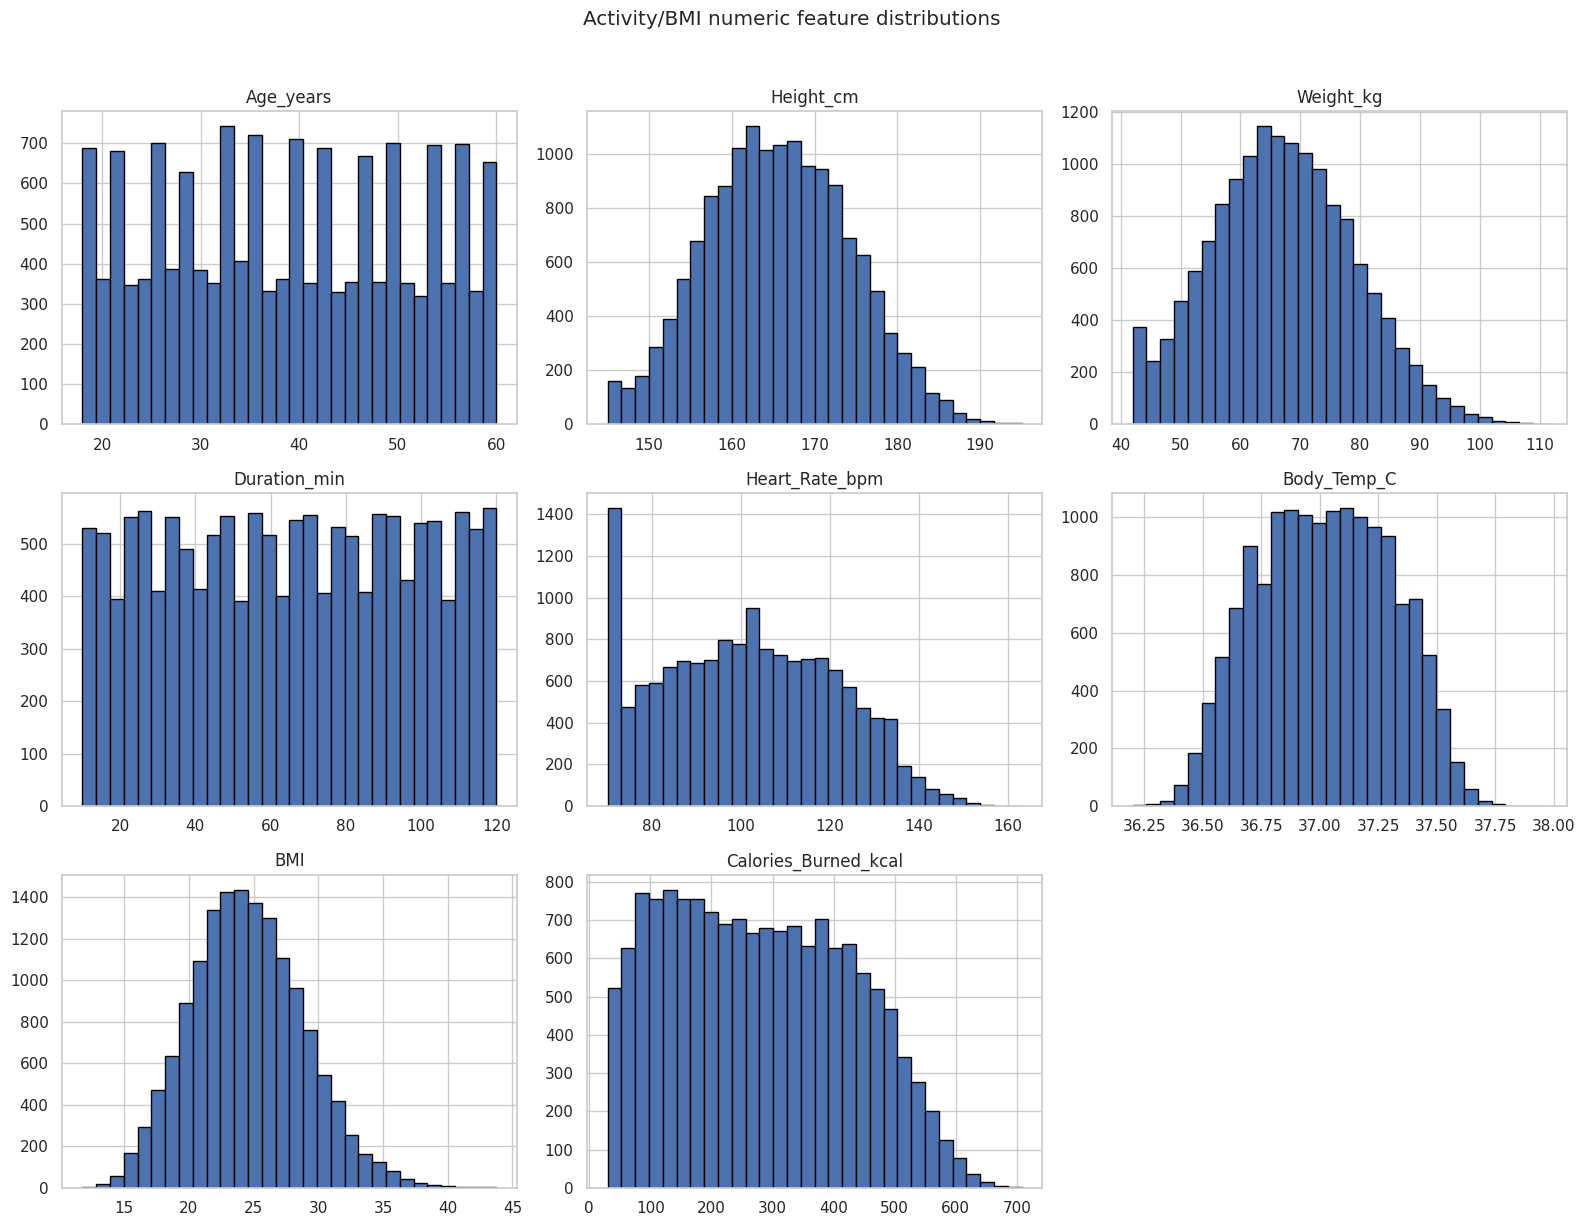

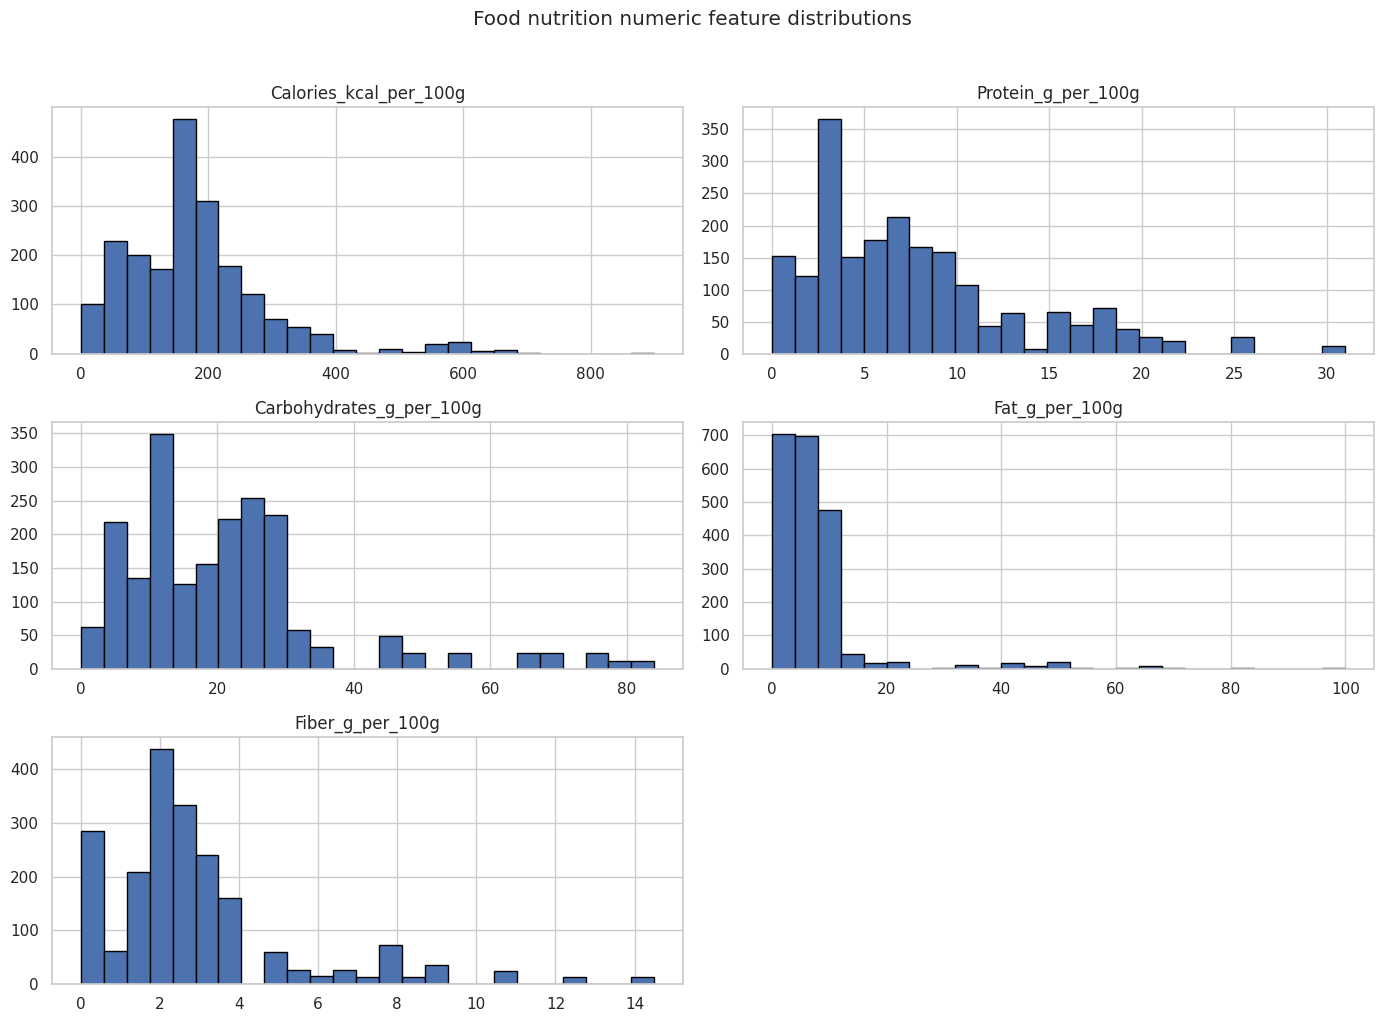

Activity/BMI missing values


,missing
Record_ID,0
Gender,14
Age_years,7
Height_cm,7
Weight_kg,11
Duration_min,10
Heart_Rate_bpm,14
Body_Temp_C,17
BMI,12
Calories_Burned_kcal,8


Food missing values


,missing
Food_ID,0
Food_Name,5
Category,2
Calories_kcal_per_100g,0
Protein_g_per_100g,2
Carbohydrates_g_per_100g,1
Fat_g_per_100g,1
Fiber_g_per_100g,1


In [6]:
numeric_bmi = bmi_raw.select_dtypes(include=np.number).columns.tolist()
if numeric_bmi:
    bmi_raw[numeric_bmi].hist(figsize=(16, 12), bins=30, edgecolor="black")
    plt.suptitle("Activity/BMI numeric feature distributions", y=1.02)
    plt.tight_layout()
    plt.show()

numeric_food = food_raw.select_dtypes(include=np.number).columns.tolist()
if numeric_food:
    food_raw[numeric_food].hist(figsize=(14, 10), bins=25, edgecolor="black")
    plt.suptitle("Food nutrition numeric feature distributions", y=1.02)
    plt.tight_layout()
    plt.show()

print("Activity/BMI missing values")
display(bmi_raw.isna().sum().to_frame("missing"))
print("Food missing values")
display(food_raw.isna().sum().to_frame("missing"))

## 5. Clean and validate the activity/BMI dataset

In [7]:
bmi_df = bmi_raw.copy()
bmi_df.columns = [c.strip() for c in bmi_df.columns]
bmi_df = bmi_df.drop_duplicates().copy()

# Convert expected numeric columns safely when present.
bmi_numeric_candidates = [
    "Age_years", "Height_cm", "Weight_kg", "Duration_min",
    "Heart_Rate_bpm", "Body_Temp_C", "BMI", "Calories_Burned_kcal"
]
for col in bmi_numeric_candidates:
    if col in bmi_df.columns:
        bmi_df[col] = pd.to_numeric(bmi_df[col], errors="coerce")

if "Gender" in bmi_df.columns:
    bmi_df["Gender"] = bmi_df["Gender"].astype("string").str.strip().str.title()
    bmi_df["Gender"] = bmi_df["Gender"].replace({"": pd.NA, "Nan": pd.NA, "None": pd.NA})

# Recalculate BMI from height/weight when both fields are available.
if {"Height_cm", "Weight_kg"}.issubset(bmi_df.columns):
    valid_hw = (bmi_df["Height_cm"] > 0) & (bmi_df["Weight_kg"] > 0)
    bmi_df.loc[valid_hw, "BMI"] = (
        bmi_df.loc[valid_hw, "Weight_kg"] / (bmi_df.loc[valid_hw, "Height_cm"] / 100) ** 2
    )
    bmi_df.loc[~valid_hw, "BMI"] = np.nan

# Remove physically impossible values as missing rather than silently treating them as true.
validity_rules = {
    "Age_years": (1, 110),
    "Height_cm": (80, 250),
    "Weight_kg": (15, 350),
    "Duration_min": (0, 600),
    "Heart_Rate_bpm": (25, 250),
    "Body_Temp_C": (25, 45),
    "Calories_Burned_kcal": (0, 5000),
}
for col, (low, high) in validity_rules.items():
    if col in bmi_df.columns:
        bmi_df.loc[~bmi_df[col].between(low, high), col] = np.nan

print("Shape after exact duplicate removal and validation:", bmi_df.shape)
display(bmi_df.isna().sum().to_frame("missing_after_validation"))
display(bmi_df.head())

Shape after exact duplicate removal and validation: (15000, 10)


,missing_after_validation
Record_ID,0
Gender,14
Age_years,7
Height_cm,7
Weight_kg,11
Duration_min,10
Heart_Rate_bpm,14
Body_Temp_C,17
BMI,18
Calories_Burned_kcal,8


,Record_ID,Gender,Age_years,Height_cm,Weight_kg,Duration_min,Heart_Rate_bpm,Body_Temp_C,BMI,Calories_Burned_kcal
0,C11500,Female,50.0,154.1,69.1,105.0,126.0,37.37,29.098645,439.9
1,C06476,Female,40.0,155.0,68.1,94.0,119.0,37.34,28.345473,424.4
2,C13168,Female,33.0,160.7,66.0,99.0,124.0,37.19,25.557136,479.9
3,C00863,Female,47.0,160.5,65.8,117.0,120.0,37.57,25.543230,475.4
4,C05971,Male,51.0,177.4,70.3,101.0,123.0,37.48,22.338196,475.3


## 6. Clean the food nutrition database

In [8]:
food_df = food_raw.copy()
food_df.columns = [c.strip() for c in food_df.columns]
food_df = food_df.drop_duplicates().copy()

for col in food_df.columns:
    if col not in ["Food_ID", "Food_Name", "Category"]:
        food_df[col] = pd.to_numeric(food_df[col], errors="coerce")

for col in ["Food_Name", "Category"]:
    if col in food_df.columns:
        food_df[col] = food_df[col].astype("string").str.strip()
        food_df[col] = food_df[col].replace({"": pd.NA, "Nan": pd.NA, "None": pd.NA})

if "Food_Name" in food_df.columns:
    food_df = food_df[food_df["Food_Name"].notna()].copy()
if "Food_ID" in food_df.columns:
    food_df["Food_ID"] = food_df["Food_ID"].astype("string").str.strip()

# Nutrient amounts per 100 g should not be negative. High calorie values can be legitimate (e.g. oils),
# so we do not remove them solely for being high.
nutrient_cols = [
    "Calories_kcal_per_100g", "Protein_g_per_100g",
    "Carbohydrates_g_per_100g", "Fat_g_per_100g", "Fiber_g_per_100g"
]
for col in nutrient_cols:
    if col in food_df.columns:
        food_df.loc[food_df[col] < 0, col] = np.nan

# Fill missing numeric nutrient values with the column median; fill missing categories with "Unknown".
for col in nutrient_cols:
    if col in food_df.columns:
        food_df[col] = food_df[col].fillna(food_df[col].median())
if "Category" in food_df.columns:
    food_df["Category"] = food_df["Category"].fillna("Unknown")

print("Shape after cleaning:", food_df.shape)
display(food_df.isna().sum().to_frame("missing_after_cleaning"))
display(food_df.head())

Shape after cleaning: (2025, 8)


,missing_after_cleaning
Food_ID,0
Food_Name,0
Category,0
Calories_kcal_per_100g,0
Protein_g_per_100g,0
Carbohydrates_g_per_100g,0
Fat_g_per_100g,0
Fiber_g_per_100g,0


,Food_ID,Food_Name,Category,Calories_kcal_per_100g,Protein_g_per_100g,Carbohydrates_g_per_100g,Fat_g_per_100g,Fiber_g_per_100g
0,F0001,"Rice, cooked",Rice & Grains,130.0,2.7,28.2,0.3,0.4
1,F0002,"Brown rice, cooked",Rice & Grains,123.0,2.7,25.6,1.0,1.6
2,F0003,"Roti, whole wheat",Grains & Bread,297.0,9.6,55.0,4.5,9.0
3,F0004,Chapati,Grains & Bread,297.0,9.6,55.0,4.5,9.0
4,F0005,Naan,Grains & Bread,310.0,8.7,50.0,8.0,2.0


## 7. Feature analysis and target definition

Training rows with known target: 14992
Features: ['Gender', 'Age_years', 'Height_cm', 'Weight_kg', 'Duration_min', 'Heart_Rate_bpm', 'Body_Temp_C', 'BMI']
Numeric features: ['Age_years', 'Height_cm', 'Weight_kg', 'Duration_min', 'Heart_Rate_bpm', 'Body_Temp_C', 'BMI']
Categorical features: ['Gender']


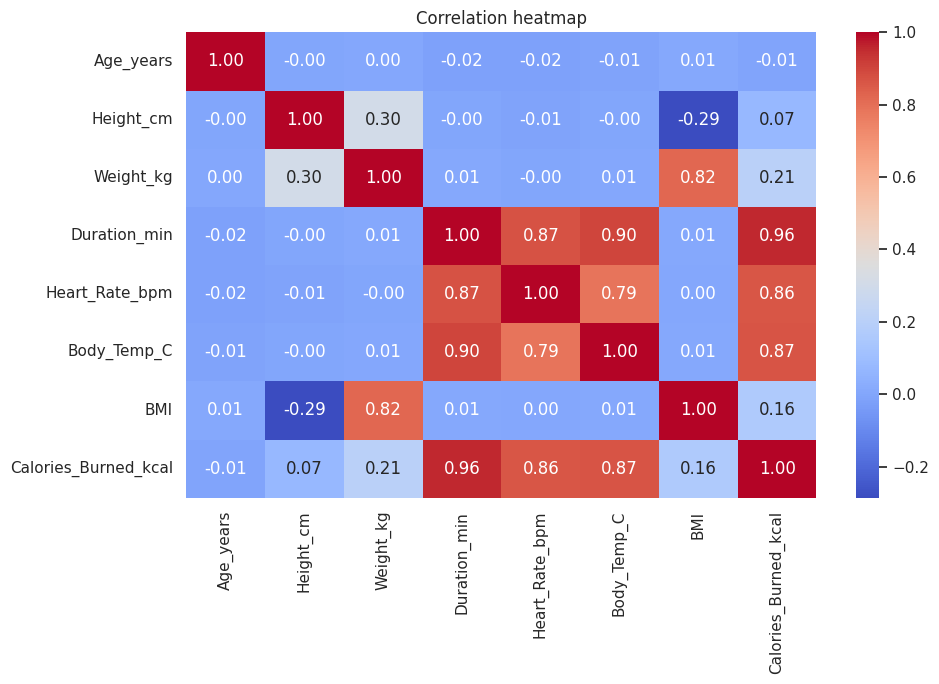

In [9]:
target = "Calories_Burned_kcal"
if target not in bmi_df.columns:
    raise KeyError(f"Target column '{target}' was not found. Available columns: {bmi_df.columns.tolist()}")

# ID is not a predictive feature. BMI is retained because it is a meaningful derived feature,
# though it is mathematically derived from height/weight.
drop_features = [c for c in ["Record_ID", target] if c in bmi_df.columns]
X = bmi_df.drop(columns=drop_features)
y = bmi_df[target]

# Rows without target cannot be used for supervised training.
model_data = pd.concat([X, y.rename(target)], axis=1).dropna(subset=[target]).copy()
X = model_data.drop(columns=[target])
y = model_data[target]

# Exclude any remaining all-null columns to avoid preprocessing failures.
X = X.dropna(axis=1, how="all")
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print("Training rows with known target:", len(y))
print("Features:", X.columns.tolist())
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

if numeric_features:
    corr_df = model_data[numeric_features + [target]].corr(numeric_only=True)
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr_df, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation heatmap")
    plt.tight_layout()
    plt.show()

## 8. Train/test split and preprocessing

In [10]:
# Convert pandas "string" columns to plain object with np.nan (sklearn imputer needs this)
X = X.copy()
for c in categorical_features:
    X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="drop")

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (11993, 8) Test: (2999, 8)


## 9. Compare baseline and state-of-the-art classical regression models

,Model,MAE,RMSE,R2
0,Gradient Boosting,20.453,25.510,0.9711
1,Random Forest,20.934,26.229,0.9695
2,Extra Trees,21.125,26.389,0.9691
3,Linear Regression,23.064,29.225,0.9621
4,Ridge Regression,23.064,29.225,0.9621
5,Decision Tree,26.296,32.958,0.9518
6,Dummy baseline,129.412,150.163,-0.0003


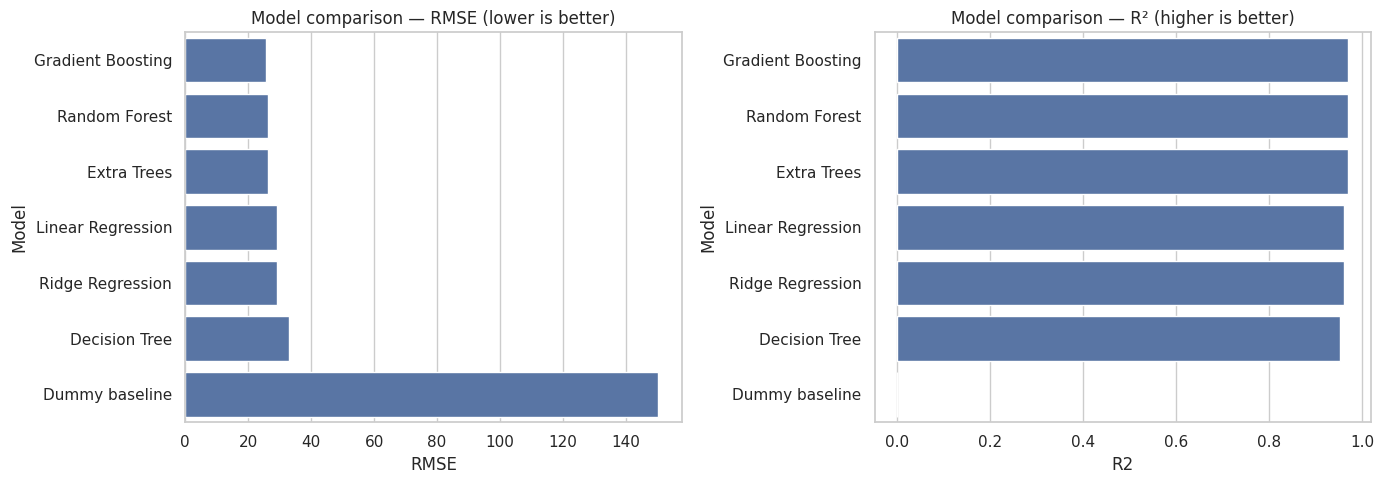

Best model selected by lowest test RMSE: Gradient Boosting


In [11]:
models = {
    "Dummy baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE, min_samples_leaf=3),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=RANDOM_STATE, min_samples_leaf=2, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300, random_state=RANDOM_STATE, min_samples_leaf=2, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

results = []
fitted_models = {}
for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": rmse,
        "R2": r2_score(y_test, pred)
    })
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.style.format({"MAE":"{:.3f}", "RMSE":"{:.3f}", "R2":"{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=results_df, x="RMSE", y="Model", ax=axes[0])
axes[0].set_title("Model comparison — RMSE (lower is better)")
sns.barplot(data=results_df, x="R2", y="Model", ax=axes[1])
axes[1].set_title("Model comparison — R² (higher is better)")
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
print("Best model selected by lowest test RMSE:", best_model_name)

## 10. Evaluate the selected model

Selected model: Gradient Boosting
MAE : 20.453 kcal
RMSE: 25.510 kcal
R²  : 0.9711


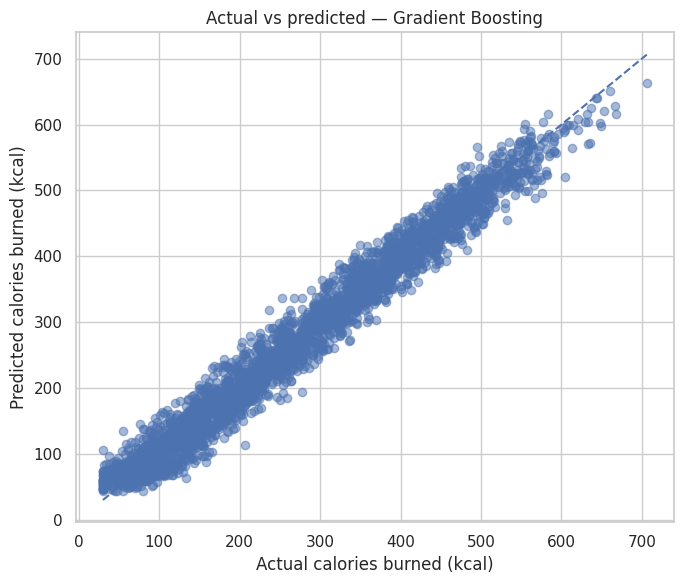

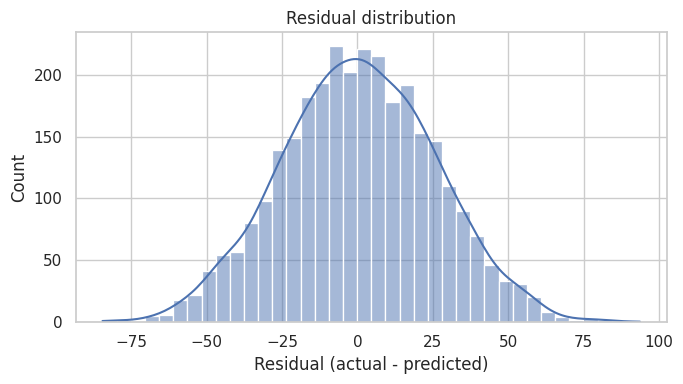

In [12]:
best_pred = best_model.predict(X_test)
print(f"Selected model: {best_model_name}")
print(f"MAE : {mean_absolute_error(y_test, best_pred):.3f} kcal")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_pred)):.3f} kcal")
print(f"R²  : {r2_score(y_test, best_pred):.4f}")

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.5)
low = min(float(y_test.min()), float(np.min(best_pred)))
high = max(float(y_test.max()), float(np.max(best_pred)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual calories burned (kcal)")
plt.ylabel("Predicted calories burned (kcal)")
plt.title(f"Actual vs predicted — {best_model_name}")
plt.tight_layout()
plt.show()

residuals = y_test - best_pred
plt.figure(figsize=(7, 4))
sns.histplot(residuals, kde=True)
plt.xlabel("Residual (actual - predicted)")
plt.title("Residual distribution")
plt.tight_layout()
plt.show()

## 11. Feature importance (when the selected model supports it)

,Feature,Importance
3,num__Duration_min,0.921102
2,num__Weight_kg,0.048571
4,num__Heart_Rate_bpm,0.027513
8,cat__Gender_Male,0.001665
5,num__Body_Temp_C,0.000354
7,cat__Gender_Female,0.000346
0,num__Age_years,0.000197
6,num__BMI,0.000175
1,num__Height_cm,0.000078


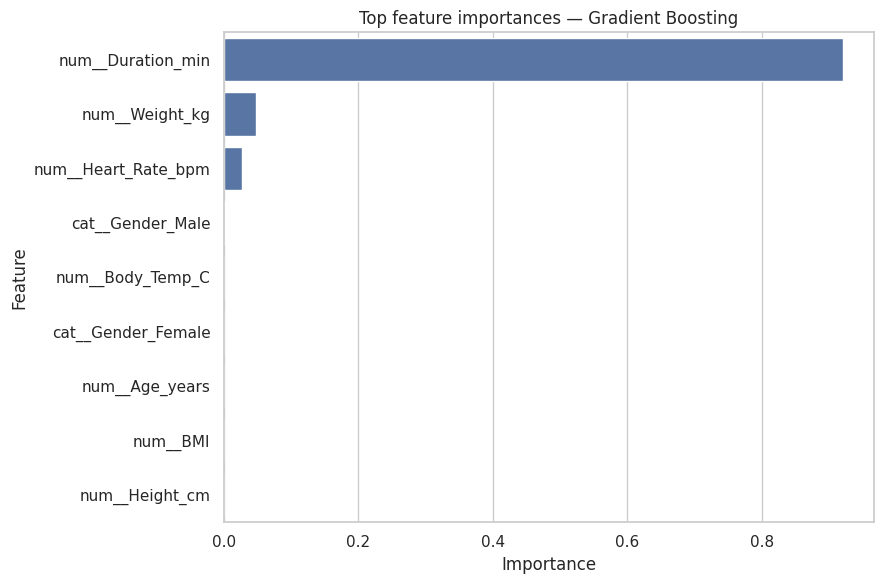

In [13]:
try:
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_estimator = best_model.named_steps["model"]
    feature_names = fitted_preprocessor.get_feature_names_out()
    if hasattr(fitted_estimator, "feature_importances_"):
        importance = pd.DataFrame({
            "Feature": feature_names,
            "Importance": fitted_estimator.feature_importances_
        }).sort_values("Importance", ascending=False).head(15)
        display(importance)
        plt.figure(figsize=(9, 6))
        sns.barplot(data=importance, x="Importance", y="Feature")
        plt.title(f"Top feature importances — {best_model_name}")
        plt.tight_layout()
        plt.show()
    elif hasattr(fitted_estimator, "coef_"):
        coef = np.ravel(fitted_estimator.coef_)
        importance = pd.DataFrame({
            "Feature": feature_names,
            "Absolute coefficient": np.abs(coef),
            "Coefficient": coef
        }).sort_values("Absolute coefficient", ascending=False).head(15)
        display(importance)
except Exception as e:
    print("Feature importance unavailable for this model:", e)

## 12. Save cleaned data, model, and evaluation outputs

In [14]:
os.makedirs("artifacts", exist_ok=True)
bmi_df.to_csv("artifacts/activity_bmi_cleaned.csv", index=False)
food_df.to_csv("artifacts/food_nutrition_cleaned.csv", index=False)
results_df.to_csv("artifacts/model_comparison.csv", index=False)
joblib.dump(best_model, "artifacts/best_calories_burned_model.joblib")

metadata = {
    "best_model": best_model_name,
    "target": target,
    "features": X.columns.tolist(),
    "test_MAE": float(mean_absolute_error(y_test, best_pred)),
    "test_RMSE": float(np.sqrt(mean_squared_error(y_test, best_pred))),
    "test_R2": float(r2_score(y_test, best_pred)),
    "random_state": RANDOM_STATE,
    "test_size": 0.20
}
with open("artifacts/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved files:")
print(os.listdir("artifacts"))

Saved files:
['best_calories_burned_model.joblib', 'activity_bmi_cleaned.csv', 'food_nutrition_cleaned.csv', 'model_comparison.csv', 'model_metadata.json']


## 13. Food logging and nutrition calculator

In [15]:
# Robust food lookup; choose a food name from the cleaned database.
food_name_col = "Food_Name"
cal_col = "Calories_kcal_per_100g"

food_choices = sorted(food_df[food_name_col].dropna().astype(str).unique().tolist())
print(f"Food items available: {len(food_choices)}")
print("Example foods:", food_choices[:20])

def nutrition_for_food(food_name, quantity_g):
    if quantity_g <= 0:
        raise ValueError("Quantity must be greater than zero grams.")
    matches = food_df[food_df[food_name_col].astype(str).str.casefold() == str(food_name).casefold()]
    if matches.empty:
        raise ValueError(f"Food not found: {food_name}")
    row = matches.iloc[0]
    multiplier = float(quantity_g) / 100.0
    output = {"Food_Name": str(row[food_name_col]), "Quantity_g": float(quantity_g)}
    for col in nutrient_cols:
        if col in food_df.columns:
            output[col.replace("_per_100g", "_for_quantity")] = float(row[col]) * multiplier
    return output

# Example usage — replace with any food name printed above.
if food_choices:
    display(pd.DataFrame([nutrition_for_food(food_choices[0], 150)]))

Food items available: 2025
Example foods: ['Almonds', 'Almonds - baked', 'Almonds - boiled', 'Almonds - grilled', 'Almonds - homemade style', 'Almonds - lightly seasoned', 'Almonds - plain', 'Almonds - roasted', 'Almonds - steamed', 'Almonds - traditional style', 'Almonds - with herbs', 'Almonds - without added oil', 'Aloo paratha', 'Aloo paratha - baked', 'Aloo paratha - boiled', 'Aloo paratha - grilled', 'Aloo paratha - homemade style', 'Aloo paratha - lightly seasoned', 'Aloo paratha - plain', 'Aloo paratha - roasted']


,Food_Name,Quantity_g,Calories_kcal_for_quantity,Protein_g_for_quantity,Carbohydrates_g_for_quantity,Fat_g_for_quantity,Fiber_g_for_quantity
0,Almonds,150.0,868.5,31.8,32.4,74.85,18.75


## 14. Estimate daily energy needs (formula-based, not ML-predicted)

In [16]:
def estimate_daily_calories(sex, age_years, height_cm, weight_kg, activity_level="Moderately active"):
   # \"\"\"Mifflin-St Jeor estimate. This is an estimate, not medical advice.\"\"\"
    if age_years <= 0 or height_cm <= 0 or weight_kg <= 0:
        raise ValueError("Age, height, and weight must be positive.")
    # Mifflin-St Jeor resting energy expenditure
    sex_term = 5 if str(sex).lower() in {"male", "m"} else -161
    ree = 10 * weight_kg + 6.25 * height_cm - 5 * age_years + sex_term
    activity_multipliers = {
        "Sedentary": 1.2,
        "Lightly active": 1.375,
        "Moderately active": 1.55,
        "Very active": 1.725,
        "Extra active": 1.9
    }
    if activity_level not in activity_multipliers:
        raise ValueError(f"Choose an activity level from {list(activity_multipliers)}")
    return round(ree * activity_multipliers[activity_level])

# Example only; edit these inputs.
example_daily_target = estimate_daily_calories(
    sex="female", age_years=25, height_cm=165, weight_kg=65,
    activity_level="Moderately active"
)
print("Example estimated daily energy needs:", example_daily_target, "kcal/day")

Example estimated daily energy needs: 2163 kcal/day


## 15. BMI calculator and BMI category (screening only)

In [17]:
def calculate_bmi(weight_kg, height_cm):
    if weight_kg <= 0 or height_cm <= 0:
        raise ValueError("Weight and height must be positive.")
    return round(weight_kg / ((height_cm / 100) ** 2), 2)

def bmi_category(bmi):
    if bmi < 18.5:
        return "Underweight"
    if bmi < 25:
        return "Normal range"
    if bmi < 30:
        return "Overweight"
    return "Obesity range"

sample_bmi = calculate_bmi(65, 165)
print("Example BMI:", sample_bmi, "| Category:", bmi_category(sample_bmi))

Example BMI: 23.88 | Category: Normal range


## 16. Download outputs from Colab

In [18]:
from google.colab import files
import shutil
shutil.make_archive("calories_tracker_artifacts", "zip", "artifacts")
files.download("calories_tracker_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
   import sklearn; print(sklearn.__version__)

## Notes for your report
- Report the actual test-set MAE, RMSE and R² shown by your run; do not invent performance values.
- The model predicts calories burned from the activity dataset. It does not predict calories consumed.
- The food calculator computes intake by multiplying per-100-g nutrition values by quantity/100.
- The daily calorie estimate uses the Mifflin–St Jeor equation plus an activity multiplier. It is an estimate, not a personalized medical prescription.
- Describe preprocessing, duplicate removal, missing-value handling, BMI recalculation, train/test split, models compared, evaluation metrics, limitations, and deployment.